# PL1 — From Tokens to Text
### UMinho · Generative AI · MSc in Artificial Intelligence · Lab 1

In this lab you build the two ends of every language model, the **tokenizer** (text → integers) and the **decoder** (probabilities → text) — and, in between, a small **n-gram language model** evaluated with **perplexity**.

| Part | Topic | Suggested time |
|---|---|---|
| 1 | Byte-Pair Encoding from scratch 
| 2 | Production tokenizers and the multilingual token tax 
| 3 | N-gram language models and perplexity 
| 4 | Decoding strategies 
| 5 | Scaling laws, back of the envelope (**homework**) 

**Instructions:** Fill every cell marked `# TODO` and every *Your answer* cell. Cells starting with `# CHECK` test your implementation: run them, they must pass silently. Keep answers short (2–5 sentences) and grounded in the numbers you obtained.

**Names / student numbers:** _…_

## 0. Setup
Run this once. On Google Colab, upload the `data/` folder (or mount Drive) so that `data/tiny_shakespeare.txt` and `data/parallel_sentences.tsv` are reachable.

In [1]:
# If needed: !pip install -q tiktoken numpy matplotlib
import math, time, random
from collections import Counter, defaultdict
import numpy as np
import matplotlib.pyplot as plt
import zipfile

random.seed(0)
rng = np.random.default_rng(0)

with zipfile.ZipFile("data.zip") as z:
    with z.open("data/tiny_shakespeare.txt") as f:
        corpus = f.read().decode("utf-8")

print(f"{len(corpus):,} characters")
print(corpus[:250])

1,115,394 characters
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.



---
## Part 1 — Byte-Pair Encoding from scratch

Modern LLM tokenizers (GPT-2 onwards, Llama, Mistral, …) use **byte-level BPE**. We start from the UTF-8 bytes of the text, so the initial vocabulary is the 256 possible byte values and *no string is ever out-of-vocabulary*. Training repeats one step:

1. count every pair of adjacent token ids;
2. take the most frequent pair `(a, b)`;
3. create a new token id for it and replace every occurrence of `(a, b)` by that id.

After `m` merges the vocabulary has `256 + m` entries. Encoding new text applies the learned merges **in the order they were learned**.

We train on the first 50 000 characters of the corpus to keep things fast (pure Python).

In [2]:
bpe_train_text = corpus[:50_000]
bpe_test_text  = corpus[-20_000:]          # held-out slice from the end of the corpus

### Exercise 1.1 — The two primitives
Implement `get_pair_counts(ids)` (a `Counter` over adjacent pairs) and `merge(ids, pair, new_id)` (left-to-right, non-overlapping replacement).

In [3]:
def get_pair_counts(ids):
    if not ids:
        return Counter()

    pair_counts = Counter()
    for i in range(len(ids) - 1):
        pair_counts[(ids[i], ids[i+1])] += 1
    return pair_counts


def merge(ids, pair, new_id):
    if not ids:
        return []
    merged = []
    i = 0
    while i < len(ids):
        if i < len(ids) - 1 and (ids[i], ids[i+1]) == pair:
            merged.append(new_id)
            i += 2
        else:
            merged.append(ids[i])
            i += 1
    return merged


In [4]:
# CHECK 1.1
assert get_pair_counts([1, 2, 3, 1, 2]) == Counter({(1, 2): 2, (2, 3): 1, (3, 1): 1})
assert merge([1, 2, 3, 1, 2], (1, 2), 99) == [99, 3, 99]
assert merge([5, 5, 5], (5, 5), 7) == [7, 5]           # non-overlapping, left to right
print("1.1 OK")

1.1 OK


### Exercise 1.2 — Training, encoding, decoding
In Exercise 1.1, you implemented the two basic operations needed by BPE:

* get_pair_counts(ids) counts how often each adjacent pair of token IDs occurs.
* merge(ids, pair, new_id) replaces all non-overlapping occurrences of a pair with a new token ID.

Now, use these two operations to build a complete, simplified byte-level BPE tokenizer.
The tokenizer has four main steps:

* 1. Training: learn which pairs should be merged.
* 2. Vocabulary construction: determine which bytes each token ID represents.
* 3. Encoding: convert new text into token IDs using the learned merges.
* 4. Decoding: convert token IDs back into text.

Implement:
* `train_bpe(text, vocab_size)` → It should learn the BPE merge rules from text and return an **ordered** dictionary called `merges`, `dict` `{(a, b): new_id}`, with new ids 256, 257, …
* `build_vocab(merges)` → `dict` `{id: bytes}` (ids 0–255 are single bytes; a merged id is the concatenation of its two parts).
* `encode(text, merges)` → list of ids. At each step, among the pairs present, merge the one that was **learned earliest** (lowest new id). Stop when no present pair is in `merges`.
* `decode(ids, vocab)` → string (use `errors="replace"`).

In [5]:
def train_bpe(text, vocab_size, verbose=False):
    assert vocab_size >= 256
    ids = list(text.encode("utf-8"))
    merges = {}

    for new_id in range(256, vocab_size):
        pair_counts = get_pair_counts(ids)
        if not pair_counts:
            break
        most_common_pair = pair_counts.most_common(1)[0][0]
        merges[most_common_pair] = new_id
        ids = merge(ids, most_common_pair, new_id)

    return merges


def build_vocab(merges):
    vocab = {i: bytes([i]) for i in range(256)}

    for (a, b), new_id in merges.items():
        vocab[new_id] = vocab[a] + vocab[b]

    return vocab


def encode(text, merges):
    ids = list(text.encode("utf-8"))

    for (a, b), new_id in merges.items():
        while True:
            pair_counts = get_pair_counts(ids)
            if pair_counts.get((a, b), 0) == 0:
                break
            ids = merge(ids, (a, b), new_id)

    return ids


def decode(ids, vocab):
    byte_string = b"".join(vocab[i] for i in ids)
    return byte_string.decode("utf-8", errors="replace")


In [6]:
t0 = time.time()
merges = train_bpe(bpe_train_text, vocab_size=1024, verbose=True)
vocab = build_vocab(merges)
print(f"trained {len(merges)} merges in {time.time() - t0:.1f}s")

trained 768 merges in 3.7s


In [7]:
# CHECK 1.2
assert len(merges) == 768 and len(vocab) == 1024
assert list(merges.values()) == list(range(256, 1024))
for s in ["To be, or not to be", "Olá, ação! 🚀", bpe_test_text[:500]]:
    assert decode(encode(s, merges), vocab) == s, s
assert len(encode(bpe_test_text[:2000], merges)) < len(bpe_test_text[:2000].encode()) * 0.7
print("1.2 OK")

1.2 OK


### Exercise 1.3 — What did BPE learn?
Print the first 25 learned tokens and the 25 **longest** tokens in the vocabulary (as strings).

In [8]:
firsts_25 = {key: merges[key] for key in list(merges.keys())[:25]}
print(firsts_25)
print(repr(decode(firsts_25.values(), vocab)))

longest_25 = {key: merges[key] for key in sorted(merges.keys(), key=lambda k: len(vocab[merges[k]]), reverse=True)[:25]}
print(longest_25)
print(repr(decode(longest_25.values(), vocab)))

{(101, 32): 256, (116, 104): 257, (115, 32): 258, (116, 32): 259, (111, 117): 260, (44, 32): 261, (100, 32): 262, (101, 114): 263, (105, 110): 264, (97, 110): 265, (32, 257): 266, (101, 110): 267, (58, 10): 268, (111, 114): 269, (97, 114): 270, (121, 32): 271, (10, 10): 272, (111, 110): 273, (108, 108): 274, (111, 32): 275, (121, 260): 276, (104, 97): 277, (101, 115): 278, (46, 272): 279, (44, 10): 280}
'e ths t ou, d erinan then:\norary \n\nonllo youhaes.\n\n,\n'
{(473, 472): 684, (369, 786): 969, (405, 472): 786, (559, 948): 1014, (350, 400): 435, (279, 494): 577, (487, 563): 604, (419, 583): 621, (419, 506): 739, (559, 400): 931, (683, 782): 955, (439, 678): 958, (350, 418): 469, (622, 624): 651, (419, 682): 741, (746, 285): 785, (279, 511): 595, (656, 305): 981, (1016, 951): 1017, (493, 402): 494, (86, 506): 678, (473, 83): 774, (487, 653): 793, (947, 521): 948, (399, 289): 400}
'.\n\nFirst Citizen:\n?\n\nFirst Citizen:\nFirst Citizen:\n?\n\nMessenger:\n.\n\nMENENIUS:\n.\n\nCOMINIU

**Q1.3.** Describe what the first merges capture and what the longest tokens capture. Why do so many tokens start with a space? What would change if you trained on Python source code instead?

**Your answer:**

The first merges capture frequent short byte patterns, such as `th` and common letter-plus-space combinations; they are not necessarily whole words. The longest tokens combine frequent sequences from the Shakespeare training text, including parts of character names and speaker labels with punctuation or line breaks. Many tokens include a leading space because spaces occur consistently between words, so merging the space with the following letters is a frequent and useful pattern. If trained on Python source code, BPE would instead learn recurring code patterns such as indentation and whitespace, keywords, identifiers, and punctuation, making code more compact to tokenize.

### Exercise 1.4 — Vocabulary size vs. sequence length
A useful property: the merges are **prefix-consistent**. The first `k` merges of a 1024-token run are exactly the merges of a `256 + k`-token run. So you can train once and evaluate many vocabulary sizes by truncating `merges`.

Compute the compression ratio **bytes per token** on `bpe_test_text` for vocab sizes `[256, 320, 384, 512, 768, 1024]` and plot it.

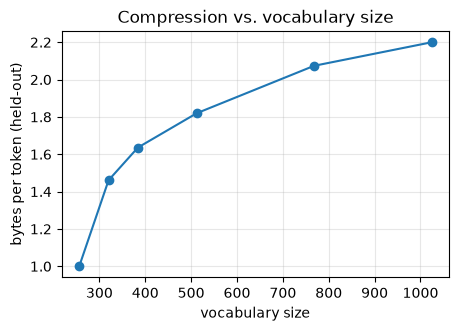

 256  1.00 bytes/token
 320  1.46 bytes/token
 384  1.64 bytes/token
 512  1.82 bytes/token
 768  2.07 bytes/token
1024  2.20 bytes/token


In [9]:
vocab_sizes = [256, 320, 384, 512, 768, 1024]
test_bytes = len(bpe_test_text.encode("utf-8"))
ratios = []

for size in vocab_sizes:
    num_merges_to_keep = size - 256
    kept_merges = {key: merges[key] for key in list(merges.keys())[:num_merges_to_keep]}
    encoded_test_text = encode(bpe_test_text, kept_merges)
    ratios.append(test_bytes / len(encoded_test_text))

plt.figure(figsize=(5, 3.2))
plt.plot(vocab_sizes, ratios, "o-")
plt.xlabel("vocabulary size"); plt.ylabel("bytes per token (held-out)")
plt.title("Compression vs. vocabulary size"); plt.grid(alpha=.3); plt.show()
for vs, r in zip(vocab_sizes, ratios):
    print(f"{vs:4d}  {r:.2f} bytes/token")

In [10]:
# CHECK 1.4
assert abs(ratios[0] - 1.0) < 1e-9 and all(b > a for a, b in zip(ratios, ratios[1:]))
print("1.4 OK")

1.4 OK


**Q1.4.** Production vocabularies range from ~32k (Llama 2) to ~200k (GPT-4o's `o200k_base`) and more. Using your curve, explain the trade-off a model designer faces when choosing vocabulary size. Name one cost that grows with the vocabulary and one that shrinks.

**Your answer:**

_…_

---
## Part 2 — Production tokenizers and the multilingual token tax

We now use OpenAI's `tiktoken` to load three real tokenizers: `gpt2` (50k vocab, 2019), `cl100k_base` (100k, GPT-3.5/4) and `o200k_base` (200k, GPT-4o). The first call downloads the vocabulary files, so you need internet access.

In [11]:
import tiktoken

encodings = {}
for name in ["gpt2", "cl100k_base", "o200k_base"]:
    try:
        encodings[name] = tiktoken.get_encoding(name)
        print(f"{name:12s} vocab = {encodings[name].n_vocab:,}")
    except Exception as e:
        print(f"{name:12s} could not be loaded ({type(e).__name__}); continuing without it")

gpt2         vocab = 50,257
cl100k_base  vocab = 100,277
o200k_base   vocab = 200,019


### Exercise 2.1 — Your BPE vs. production BPE
Compute bytes/token on `bpe_test_text` for each loaded encoding and compare with your 1024-token BPE.

In [12]:
compression = {"our BPE (1024)": ratios[-1]}

for name in encodings.keys():
    encoded_test_text = encodings[name].encode(bpe_test_text)
    compression[f"{name}"] = test_bytes / len(encoded_test_text)

for k, v in compression.items():
    print(f"{k:15s} {v:.2f} bytes/token")

our BPE (1024)  2.20 bytes/token
gpt2            3.07 bytes/token
cl100k_base     3.49 bytes/token
o200k_base      3.57 bytes/token


**Q2.1.** Your tokenizer was trained on Shakespeare and the test text is Shakespeare. Production tokenizers were trained on a huge, general web mix. What does the comparison tell you about the effect of vocabulary size vs. domain match?

**Your answer:**

Production tokenizers achieve higher compression on this sample. Since more bytes per token means fewer tokens for the same text, their much larger vocabularies appear to outweigh the advantage of training on the matching domain in this comparison. However, vocabulary size and training data both differ, so this result cannot isolate the effect of either factor by itself.

### Exercise 2.2 — The token tax
`data/parallel_sentences.tsv` holds the same 20 sentences in English, Portuguese, Spanish, German, Russian and Chinese. For each encoding compute the **token premium** of each language:

$$\text{premium}(\ell) = \frac{\#\text{tokens}(\ell)}{\#\text{tokens}(\text{en})}$$

summing over all 20 sentences, and plot a grouped bar chart.

20 sentences in ['en', 'pt', 'es', 'de', 'ru', 'zh']


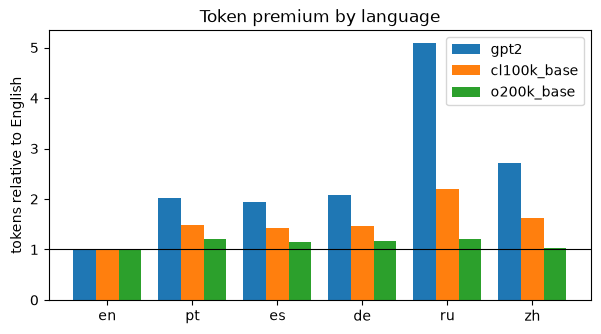

gpt2         en:1.00  pt:2.03  es:1.94  de:2.07  ru:5.09  zh:2.70
cl100k_base  en:1.00  pt:1.49  es:1.43  de:1.47  ru:2.20  zh:1.62
o200k_base   en:1.00  pt:1.21  es:1.14  de:1.17  ru:1.22  zh:1.03


In [13]:
import csv

with zipfile.ZipFile("data.zip") as z:
    with z.open("data/parallel_sentences.tsv") as f:
        rows = list(csv.DictReader(f.read().decode("utf-8").splitlines(), delimiter="\t"))
langs = list(rows[0].keys())
print(len(rows), "sentences in", langs)

premium = {}    # premium[encoding_name][lang] -> float
# TODO: total tokens per language = sum over sentences of len(enc.encode(row[lang])); divide by English total
for name in encodings.keys():
    premium[name] = {}
    for lang in langs:
        total_tokens = sum(len(encodings[name].encode(row[lang])) for row in rows)
        english_tokens = sum(len(encodings[name].encode(row["en"])) for row in rows)
        premium[name][lang] = total_tokens / english_tokens

x = np.arange(len(langs)); w = 0.8 / max(1, len(premium))
plt.figure(figsize=(7, 3.5))
for j, (name, p) in enumerate(premium.items()):
    plt.bar(x + j * w, [p[l] for l in langs], w, label=name)
plt.axhline(1, color="k", lw=.8); plt.xticks(x + w * (len(premium) - 1) / 2, langs)
plt.ylabel("tokens relative to English"); plt.legend(); plt.title("Token premium by language"); plt.show()
for name, p in premium.items():
    print(name.ljust(12), "  ".join(f"{l}:{p[l]:.2f}" for l in langs))

In [14]:
# CHECK 2.2
for name, p in premium.items():
    assert abs(p["en"] - 1) < 1e-9 and p["ru"] > 1.2, name
print("2.2 OK")

2.2 OK


**Q2.2.** (a) Which languages pay the highest premium under `gpt2`, and how much does it shrink in `o200k_base`? (b) List three concrete consequences of a high premium for a Portuguese or Russian user of an LLM API. (c) Why is it hard to fix this just by adding more tokens?

**Your answer:**

Russian has the highest `gpt2` premium at 5.09 times the English token count, followed by Chinese at 2.70; in `o200k_base`, the Russian premium falls to 1.22 (about a 76% reduction). Portuguese also improves, from 2.03 to 1.21. A high premium can mean higher API costs for the same text, fewer characters fitting in the context window (so conversation history or documents may be truncated sooner), and more output tokens, increasing response cost and potentially latency. Adding tokens is not free: a larger vocabulary increases model memory and output-layer costs, and the available vocabulary must be shared across languages, so improving coverage for one language may bring tradeoffs elsewhere.

### Exercise 2.3 — Tokenization artefacts
Many well-known LLM failure modes are tokenization problems in disguise. Use the helper below to inspect the three strings, then answer.

In [15]:
def show(s, name="cl100k_base"):
    enc = encodings.get(name) or next(iter(encodings.values()))
    pieces = [enc.decode([t]) for t in enc.encode(s)]
    print(f"{len(pieces):3d} tokens | " + " | ".join(repr(p) for p in pieces))

for s in ["How many r's are in strawberry?", "12345678 + 87654321 =", " SolidGoldMagikarp"]:
    for name in encodings:
        print(f"{name:12s}", end=" "); show(s, name)
    print()

gpt2           8 tokens | 'How' | ' many' | ' r' | "'s" | ' are' | ' in' | ' strawberry' | '?'
cl100k_base    8 tokens | 'How' | ' many' | ' r' | "'s" | ' are' | ' in' | ' strawberry' | '?'
o200k_base     8 tokens | 'How' | ' many' | ' r' | "'s" | ' are' | ' in' | ' strawberry' | '?'

gpt2           9 tokens | '123' | '45' | '678' | ' +' | ' 87' | '65' | '43' | '21' | ' ='
cl100k_base    9 tokens | '123' | '456' | '78' | ' +' | ' ' | '876' | '543' | '21' | ' ='
o200k_base     9 tokens | '123' | '456' | '78' | ' +' | ' ' | '876' | '543' | '21' | ' ='

gpt2           1 tokens | ' SolidGoldMagikarp'
cl100k_base    5 tokens | ' Solid' | 'Gold' | 'Mag' | 'ik' | 'arp'
o200k_base     5 tokens | ' Solid' | 'Gold' | 'Mag' | 'ik' | 'arp'



**Q2.3.** Using what you see, explain (a) why counting letters in a word is hard for an LLM, and (b) why arithmetic on long numbers is harder under some tokenizers than others.

**Your answer:**

(a) The tokenizer may represent a whole word such as `strawberry` as one token, rather than as individual letters. The model therefore has to infer the spelling inside the token to count a particular letter; it is difficult, but not impossible.
(b) Long numbers are split into token chunks, and the boundaries vary by tokenizer (for example, GPT-2 splits `12345678` as `123`, `45`, `678`, while the other two use `123`, `456`, `78`). Since these chunks do not necessarily align with digits or place values, the model must reason across multiple tokens, which can make arithmetic less reliable.

---
## Part 3 — N-gram language models and perplexity

A language model assigns a probability to every sequence by the chain rule, $p(x_1,\dots,x_T)=\prod_t p(x_t \mid x_{<t})$. An **n-gram** model makes the Markov assumption that only the last $n-1$ symbols matter:

$$p(x_t \mid x_{<t}) \approx p(x_t \mid x_{t-n+1:t-1}) = \frac{c(x_{t-n+1:t}) + k}{c(x_{t-n+1:t-1}) + kV}$$

with **add-k smoothing** ($V$ = vocabulary size). We work at **character level** (V ≈ 65) so the model trains in seconds.

**Perplexity** on a held-out text of $T$ symbols is the exponentiated average negative log-likelihood (i.e. the exponentiated cross-entropy):

$$\mathrm{PPL} = \exp\Big(-\frac{1}{T}\sum_t \log p(x_t\mid x_{<t})\Big)$$

A uniform model has PPL = V. Lower is better.

In [16]:
split = int(0.9 * len(corpus))
train_text, val_text = corpus[:split], corpus[split:]
chars = sorted(set(corpus))
V = len(chars)
char_to_idx = {c: i for i, c in enumerate(chars)}
print(f"V = {V}, train = {len(train_text):,} chars, val = {len(val_text):,} chars")

V = 65, train = 1,003,854 chars, val = 111,540 chars


### Exercise 3.1 — The model
Complete `NGramLM`. `fit` counts all n-grams and their (n−1)-character contexts; `prob` applies add-k smoothing; `perplexity` scores a text starting at position `start` (so that models of different order are scored on exactly the same characters).

In [17]:
class NGramLM:
    def __init__(self, n, k=1.0):
        self.n, self.k = n, k

    def fit(self, text):
        n = self.n
        # count n-grams (text[i:i+n]) and their contexts (text[i:i+n-1]) for i in range(len(text)-n+1)
        self.ngrams = {}
        self.contexts = {}
        for i in range(len(text) - n + 1):
            ngram = text[i:i+n]
            context = ngram[:-1]
            self.ngrams[ngram] = self.ngrams.get(ngram, 0) + 1
            self.contexts[context] = self.contexts.get(context, 0) + 1
        return self

    def prob(self, context, ch):
        ctx = context[-(self.n - 1):] if self.n > 1 else ""
        # add-k smoothed conditional probability (see formula above)
        return (self.ngrams.get(ctx + ch, 0) + self.k) / (self.contexts.get(ctx, 0) + self.k * len(chars))

    def dist(self, context):
        # Full next-character distribution as a NumPy vector over `chars` (used in Part 4).
        p = np.array([self.prob(context, c) for c in chars])
        return p / p.sum()

    def perplexity(self, text, start=None):
        start = self.n - 1 if start is None else start
        # average -log p(text[t] | text[:t]) for t in range(start, len(text)); return exp of it (inf if any p == 0)
        log_prob_sum = 0.0
        for t in range(start, len(text)):
            p = self.prob(text[:t], text[t])
            if p == 0:
                return float('inf')
            log_prob_sum += -np.log(p)
        return np.exp(log_prob_sum / (len(text) - start))


In [18]:
# CHECK 3.1
toy = NGramLM(2, k=0.0).fit("abab")
assert abs(toy.prob("a", "b") - 1.0) < 1e-12
uni = NGramLM(1, k=1.0).fit(train_text)
assert abs(uni.dist("").sum() - 1) < 1e-9
assert 10 < uni.perplexity(val_text[:5000]) < V
print("3.1 OK — unigram PPL:", round(uni.perplexity(val_text[:5000]), 2))

3.1 OK — unigram PPL: 27.32


### Exercise 3.2 — Order and smoothing sweep
For $n \in \{1,\dots,7\}$ and $k \in \{0.01, 0.1, 1\}$, fit on `train_text` and compute PPL on the first 20 000 characters of `val_text` and of `train_text`, always with `start=6`. Plot validation PPL vs. $n$ (one line per $k$) and, for $k=0.1$, train vs. validation PPL. *(Takes ~1 minute.)*

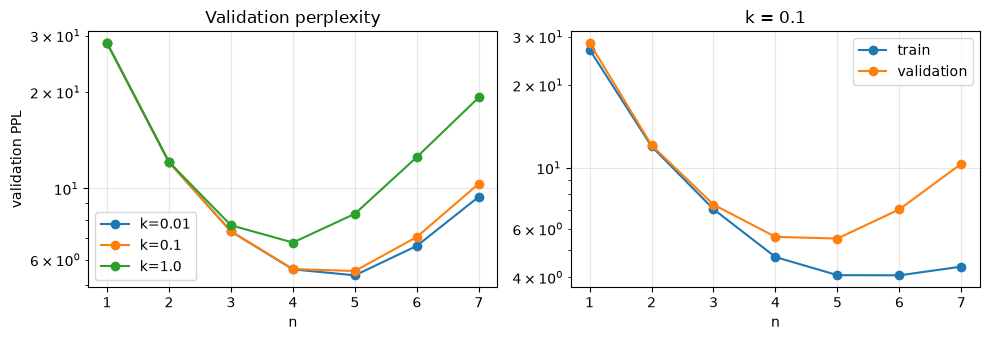

n=1 k=0.01  train=  26.92  val=  28.45
n=1 k=0.1   train=  26.92  val=  28.45
n=1 k=1.0   train=  26.92  val=  28.45
n=2 k=0.01  train=  11.97  val=  12.08
n=2 k=0.1   train=  11.97  val=  12.08
n=2 k=1.0   train=  11.99  val=  12.10
n=3 k=0.01  train=   7.02  val=   7.35
n=3 k=0.1   train=   7.07  val=   7.34
n=3 k=1.0   train=   7.38  val=   7.67
n=4 k=0.01  train=   4.52  val=   5.59
n=4 k=0.1   train=   4.73  val=   5.60
n=4 k=1.0   train=   5.87  val=   6.78
n=5 k=0.01  train=   3.49  val=   5.36
n=5 k=0.1   train=   4.07  val=   5.53
n=5 k=1.0   train=   6.81  val=   8.34
n=6 k=0.01  train=   2.88  val=   6.62
n=6 k=0.1   train=   4.06  val=   7.06
n=6 k=1.0   train=   9.42  val=  12.53
n=7 k=0.01  train=   2.46  val=   9.43
n=7 k=0.1   train=   4.37  val=  10.35
n=7 k=1.0   train=  13.18  val=  19.24


In [23]:
orders, ks = range(1, 8), [0.01, 0.1, 1.0]
val_eval, train_eval = val_text[:20_000], train_text[:20_000]
results = {}          # results[(n, k)] = (train_ppl, val_ppl)
# fit once per n (counts do not depend on k), then vary model.k
for n in orders:
    model = NGramLM(n)
    model.fit(train_text)
    for k in ks:
        model.k = k
        train_ppl = model.perplexity(train_eval, start=6)
        val_ppl = model.perplexity(val_eval, start=6)
        results[(n, k)] = (train_ppl, val_ppl)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for k in ks:
    ax[0].plot(list(orders), [results[(n, k)][1] for n in orders], "o-", label=f"k={k}")
ax[0].set(xlabel="n", ylabel="validation PPL", title="Validation perplexity", yscale="log"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(list(orders), [results[(n, 0.1)][0] for n in orders], "o-", label="train")
ax[1].plot(list(orders), [results[(n, 0.1)][1] for n in orders], "o-", label="validation")
ax[1].set(xlabel="n", title="k = 0.1", yscale="log"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()
for (n, k), (tr, va) in sorted(results.items()):
    print(f"n={n} k={k:<5} train={tr:7.2f}  val={va:7.2f}")

In [24]:
# CHECK 3.2
best = min(results, key=lambda nk: results[nk][1])
print("best (n, k):", best, "val PPL:", round(results[best][1], 2))
assert 3 <= best[0] <= 6 and results[best][1] < 6
print("3.2 OK")

best (n, k): (5, 0.01) val PPL: 5.36
3.2 OK


**Q3.2.** (a) Explain the shape of the validation curves: why does PPL first fall and then rise with $n$, and why does the penalty for a large $k$ grow with $n$? (b) What happens with $k=0$ on validation and why? (c) Convert your best validation PPL into **bits per character**. (d) Why can you *not* directly compare the perplexity of a character-level model with that of a model using your BPE tokens, and what normalisation would make them comparable?

**Your answer:**

(a) Validation PPL falls as $n$ adds useful context, reaching its minimum of 5.36 at $n=5$, $k=0.01$, then rises because longer contexts occur less often and their probability estimates become sparse. Larger $k$ hurts more at high $n$ because smoothing spreads more probability mass across all possible next characters when context counts are small, flattening the learned distribution. (b) With $k=0$, an unseen n-gram has probability zero, so encountering one in validation makes PPL infinite. (c) The best PPL corresponds to $\log_2(5.36) \approx 2.42$ bits per character. (d) Perplexity is measured per token, and character tokens and BPE tokens represent different amounts of text; compare total negative log-likelihood normalized by the same underlying text length, such as bits per byte (or bits per character).

---
## Part 4 — Decoding strategies

A language model gives a distribution $p(\cdot \mid \text{context})$; a **decoding strategy** turns it into text. Implement the four classic ones on a probability vector `p` (NumPy, sums to 1). Each returns an **index**.

* **Greedy**: argmax.
* **Temperature** $T$: sample from $\mathrm{softmax}(\log p / T)$. $T\to 0$ approaches greedy; $T=1$ is the model; $T>1$ flattens.
* **Top-k**: keep the $k$ most likely, renormalise, sample.
* **Top-p (nucleus)**: keep the *smallest* set of most-likely symbols whose cumulative probability is $\ge p$, renormalise, sample.

In [25]:
def greedy(p, rng):
    # index of the maximum
    return int(np.argmax(p))

def sample_temperature(p, rng, T=1.0):
    # work in log space for stability; subtract the max before exponentiating
    p = np.log(p + 1e-20)  # work in log space for stability
    p -= p.max()  # subtract the max before exponentiating
    p = np.exp(p / T)
    p /= p.sum()
    return int(rng.choice(len(p), p=p))

def sample_top_k(p, rng, k=5):
    # zero all but the k largest entries, renormalise, sample
    if k <= 0:
        raise ValueError("k must be positive")
    indices = np.argpartition(p, -k)[-k:]  # get the indices of the k largest entries
    q = np.zeros_like(p)
    q[indices] = p[indices]
    q /= q.sum()
    return int(rng.choice(len(p), p=q))

def nucleus(p, top_p):
    # Return the indices kept by top-p filtering (useful on its own for Q4.2).
    # sort descending, cumulative sum, keep up to and including the first index where cumsum >= top_p
    sorted_indices = np.argsort(p)[::-1]  # sort descending
    cumsum = np.cumsum(p[sorted_indices])
    keep = sorted_indices[cumsum <= top_p]
    if len(keep) == 0 or cumsum[len(keep) - 1] < top_p:
        keep = np.append(keep, sorted_indices[len(keep)])
    return keep

def sample_top_p(p, rng, top_p=0.9):
    keep = nucleus(p, top_p)
    q = np.zeros_like(p); q[keep] = p[keep]; q /= q.sum()
    return int(rng.choice(len(p), p=q))

In [26]:
# CHECK 4.1
_p = np.array([0.5, 0.3, 0.15, 0.05]); _r = np.random.default_rng(1)
assert greedy(_p, _r) == 0
assert set(nucleus(_p, 0.5)) == {0} and set(nucleus(_p, 0.8)) == {0, 1} and set(nucleus(_p, 0.81)) == {0, 1, 2}
assert all(sample_top_k(_p, _r, k=2) in (0, 1) for _ in range(200))
assert all(sample_temperature(_p, _r, T=0.01) == 0 for _ in range(50))
print("4.1 OK")

4.1 OK


### Exercise 4.2 — Generate and compare
Use the 5-gram model with $k=0.01$ as the language model. Complete `generate` and produce 400 characters from the prompt `"ROMEO:\n"` with each strategy.

In [28]:
lm = NGramLM(5, k=0.01).fit(train_text)

def generate(lm, prompt, n_chars, strategy, rng, **kw):
    text = prompt
    # repeatedly get lm.dist(text), pick an index with strategy(p, rng, **kw), append chars[idx]
    for _ in range(n_chars):
        p = lm.dist(text)
        idx = strategy(p, rng, **kw)
        text += chars[idx]
    return text

strategies = {
    "greedy":         (greedy, {}),
    "temperature 0.7": (sample_temperature, {"T": 0.7}),
    "temperature 1.3": (sample_temperature, {"T": 1.3}),
    "top-k 5":        (sample_top_k, {"k": 5}),
    "top-p 0.9":      (sample_top_p, {"top_p": 0.9}),
}
samples = {}
for name, (fn, kw) in strategies.items():
    samples[name] = generate(lm, "ROMEO:\n", 400, fn, np.random.default_rng(42), **kw)
    print(f"===== {name} =====\n{samples[name]}\n")

===== greedy =====
ROMEO:
I will the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the

===== temperature 0.7 =====
ROMEO:
This word:
Why, this housand thright of my hour name, so might to piece of his some a sighs bait fellows, let's he words, and he served with my lord,
With the servantagenerate out to his break the the will be not to beggarly unmade your reast sorrow to feel and her face been dissemble and thoughter, and me hath he is to his son thee senators promise of such the powers can by ster.

VOLUMNIA:
If sh

===== temperature 1.3 =====
ROMEO:
Sir, you jnvcoPBX&ockKytl?R!:fjxILR?.RBePpgHpnMFf3?
meglQX3-eRXkcWXG!PANqC$FGeXleNn: 'tis and for Ru

### Exercise 4.3 — Quantifying the quality–diversity trade-off
Implement two metrics and sweep temperature $T \in \{0.2, 0.4, 0.6, 0.8, 1.0, 1.2, 1.5\}$, generating 3 samples of 600 characters per value:

* **distinct-2**: number of *distinct* word bigrams divided by the total number of word bigrams (words = `text.split()`); higher = more diverse.
* **model NLL**: the average $-\log p$ **under the model at $T=1$** of the generated characters (excluding the prompt); lower = the text is more "typical" for the model.

Plot NLL (y) against distinct-2 (x), annotating each point with its $T$.

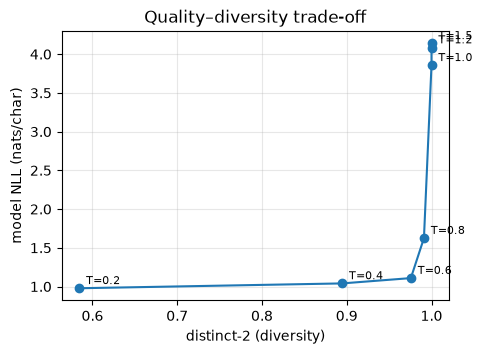

In [29]:
def distinct_2(text):
    # word bigrams via zip(words, words[1:]); return len(set) / len(list), 0.0 if empty
    words = text.split()
    bigrams = list(zip(words, words[1:]))
    return len(set(bigrams)) / len(bigrams) if bigrams else 0.0

def model_nll(lm, text, prompt_len):
    # mean of -log lm.prob(text[:t], text[t]) for t in range(prompt_len, len(text))
    return np.mean([-np.log(lm.prob(text[:t], text[t])) for t in range(prompt_len, len(text))])

temps = [0.2, 0.4, 0.6, 0.8, 1.0, 1.2, 1.5]
prompt = "ROMEO:\n"
curve = []
for T in temps:
    d, l = [], []
    for seed in range(3):
        s = generate(lm, prompt, 600, sample_temperature, np.random.default_rng(seed), T=T)
        d.append(distinct_2(s[len(prompt):])); l.append(model_nll(lm, s, len(prompt)))
    curve.append((T, np.mean(d), np.mean(l)))

plt.figure(figsize=(5, 3.5))
plt.plot([c[1] for c in curve], [c[2] for c in curve], "o-")
for T, d, l in curve:
    plt.annotate(f"T={T}", (d, l), textcoords="offset points", xytext=(5, 3), fontsize=8)
plt.xlabel("distinct-2 (diversity)"); plt.ylabel("model NLL (nats/char)")
plt.title("Quality–diversity trade-off"); plt.grid(alpha=.3); plt.show()

In [30]:
# CHECK 4.3
assert curve[0][1] < curve[-1][1] and curve[0][2] < curve[-1][2]
g = samples["greedy"][len("ROMEO:\n"):]
print("greedy distinct-2:", round(distinct_2(g), 2), "| top-p distinct-2:", round(distinct_2(samples["top-p 0.9"][7:]), 2))
print("4.3 OK")

greedy distinct-2: 0.05 | top-p distinct-2: 0.99
4.3 OK


**Q4.3.** (a) Why does greedy decoding fall into loops, even though each step picks the single most likely character? (b) Interpret your trade-off curve: which temperature range would you use for a creative-writing assistant and which for code completion? (c) Why is low model NLL *not* the same as high quality?

**Your answer:**

(a) Greedy decoding always takes the current argmax, so a repeated phrase can keep making its own continuation most likely; here the sample loops on “the shall,” and its distinct-2 is only 0.05. (b) The curve shows that increasing temperature raises diversity, but NLL climbs sharply above $T=0.8$ and the $T=1.3$ sample becomes incoherent. I would try about $T=0.6$–$0.9$ for creative writing and a lower range, around $T=0.2$–$0.5$, for code completion, where predictable continuations matter more. (c) NLL measures how predictable text is to this model, not whether it is useful, coherent, correct, or original; repetitive text can have low NLL without being high quality.

### Exercise 4.4 — Why nucleus sampling adapts
Print the nucleus size (number of characters kept at `top_p=0.9`) for the contexts below. Then answer.

In [31]:
for ctx in ["ROMEO", "KING RICHAR", "What is th", "and the ", "speak.\n\n"]:
    p = lm.dist(ctx)
    print(f"{ctx!r:16s} nucleus size = {len(nucleus(p, 0.9)):2d} | top char = {chars[int(p.argmax())]!r} ({p.max():.2f})")

'ROMEO'          nucleus size =  1 | top char = ':' (1.00)
'KING RICHAR'    nucleus size =  1 | top char = 'D' (1.00)
'What is th'     nucleus size =  4 | top char = 'e' (0.55)
'and the '       nucleus size = 19 | top char = 's' (0.09)
'speak.\n\n'     nucleus size = 15 | top char = 'K' (0.14)


**Q4.4.** Explain, using these numbers, why top-p is usually preferred over a fixed top-k.

**Your answer:**

Top-p adapts the number of candidates to how uncertain the model is: at `"ROMEO"` and `"KING RICHAR"`, one character already has probability 1.00, so the 0.9 nucleus contains just one character; after `"and the "`, the distribution is more spread out and the nucleus contains 19. A fixed top-k would use the same number in every context, potentially keeping unnecessary low-probability choices when the model is certain or cutting off useful choices when it is uncertain.

---
## Part 5 — Scaling laws, back of the envelope (homework)

Two results from the scaling-laws literature let you reason about training budgets:

1. **Training compute.** For a dense Transformer with $N$ parameters trained on $D$ tokens, $C \approx 6ND$ FLOPs (2 for the forward pass, 4 for the backward pass, per parameter per token).
2. **Chinchilla** (Hoffmann et al., 2022). For a fixed $C$, loss is minimised with roughly **20 tokens per parameter**. The paper also fits a parametric loss

$$L(N,D) = E + \frac{A}{N^{\alpha}} + \frac{B}{D^{\beta}},\qquad E=1.69,\ A=406.4,\ B=410.7,\ \alpha=0.34,\ \beta=0.28.$$

Assume training on H100 GPUs at 989 TFLOP/s peak (dense BF16) with a **model FLOPs utilisation (MFU) of 40%**.

### Exercise 5.1 — Compute-optimal allocation
Implement `chinchilla_rule(C)` (returns $N, D$ with $D = 20N$ and $6ND = C$) and `gpu_days(C, n_gpus)`. Fill in the table for $C \in \{10^{21}, 10^{23}, 10^{25}\}$ with 1 024 GPUs.

In [32]:
H100_PEAK, MFU = 989e12, 0.40

def chinchilla_rule(C):
    # 6 * N * 20N = C  ->  N = sqrt(C / 120)
    N = (C / 120) ** 0.5
    D = 20 * N
    return N, D

def gpu_days(C, n_gpus):
    # C / (peak * MFU * n_gpus) seconds, converted to days
    seconds = C / (H100_PEAK * MFU * n_gpus)
    days = seconds / (60 * 60 * 24)
    return days

print(f"{'C (FLOPs)':>10} | {'N (params)':>11} | {'D (tokens)':>11} | {'days @1024 H100':>15}")
for C in [1e21, 1e23, 1e25]:
    N, D = chinchilla_rule(C)
    print(f"{C:10.0e} | {N:11.2e} | {D:11.2e} | {gpu_days(C, 1024):15.2f}")

 C (FLOPs) |  N (params) |  D (tokens) | days @1024 H100
     1e+21 |    2.89e+09 |    5.77e+10 |            0.03
     1e+23 |    2.89e+10 |    5.77e+11 |            2.86
     1e+25 |    2.89e+11 |    5.77e+12 |          285.71


In [33]:
# CHECK 5.1
N, D = chinchilla_rule(1e23)
assert abs(6 * N * D - 1e23) / 1e23 < 1e-9 and abs(D / N - 20) < 1e-9
print("5.1 OK")

5.1 OK


### Exercise 5.2 — Using the parametric loss
For each $C$ above, find numerically the $N$ that minimises $L(N, C/6N)$ (search over a log-spaced grid of $N$ from $10^7$ to $10^{13}$). Report $N^*$, $D^*$, the tokens-per-parameter ratio $D^*/N^*$ and $L^*$. Plot $L$ vs. $N$ for the three budgets (the "IsoFLOP" curves).

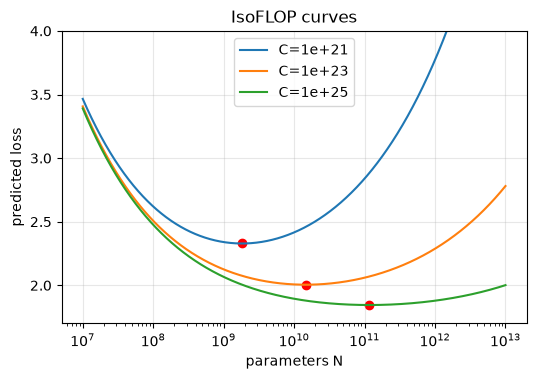

In [34]:
E, A, B, alpha, beta = 1.69, 406.4, 410.7, 0.34, 0.28
def chinchilla_loss(N, D):
    return E + A / N**alpha + B / D**beta

Ns = np.logspace(7, 13, 2000)
plt.figure(figsize=(6, 3.8))
for C in [1e21, 1e23, 1e25]:
    # D = C / (6 * Ns); evaluate the loss on the grid; argmin gives N*
    D = C / (6 * Ns)
    losses = chinchilla_loss(Ns, D)
    N_opt = Ns[np.argmin(losses)]
    plt.plot(Ns, losses, label=f"C={C:.0e}")
    plt.scatter(N_opt, np.min(losses), color='red')
plt.xscale("log"); plt.ylim(1.7, 4); plt.xlabel("parameters N"); plt.ylabel("predicted loss")
plt.title("IsoFLOP curves"); plt.legend(); plt.grid(alpha=.3); plt.show()

**Q5.2.** Does the parametric fit agree with the "20 tokens per parameter" rule at every scale? What does the difference tell you about how much to trust extrapolations from scaling-law fits? (Tip: look up Besiroglu et al., 2024, *Chinchilla Scaling: A Replication Attempt*.)

**Your answer:**

No. Minimizing the stated parametric fit gives roughly 50, 78, and 122 tokens per parameter for compute budgets of $10^{21}$, $10^{23}$, and $10^{25}$ FLOPs, respectively, so its optimum moves farther from the 20:1 rule at larger scales. This disagreement shows that fitted scaling laws are empirical and sensitive to the data and assumptions used to fit them; their extrapolations are useful hypotheses, not universal guarantees, and should be checked against independent replications and new experiments.

### Exercise 5.3 — Why "over-train"?
Meta reports training Llama 3 8B on about **15 trillion tokens**.

(a) Compute its training compute $C$, its tokens-per-parameter ratio, and the Chinchilla-optimal $N$ for that same $C$.
(b) Estimate its training time on 1 024 H100s with your `gpu_days`.
(c) Explain why a lab would deliberately train a model far smaller than compute-optimal. Your answer must mention inference.

In [35]:
# TODO: N = 8e9, D = 15e12
s = chinchilla_loss(8e9, 15e12)
print(s)


1.9485316377745965


**Your answer:**

For an 8B model trained on $15\times10^{12}$ tokens, $C\approx6ND=7.2\times10^{23}$ FLOPs and the data-to-parameter ratio is $1{,}875$ tokens per parameter. The 20:1 rule gives a same-compute optimal model size of $N^*\approx\sqrt{C/120}\approx77.5$B parameters, and training would take about 20.6 days on 1,024 H100s at 40% MFU. A lab may prefer the much smaller, heavily trained model because each inference token costs less compute and memory, reducing serving cost and latency at scale.

---
## Submission checklist
- [ ] All `# CHECK` cells pass.
- [ ] Every *Your answer* cell is filled, citing your own numbers.
- [ ] Notebook runs top to bottom (`Kernel → Restart & Run All`) in under 5 minutes.
- [ ] File named `PL1_<student1>_<student2>.ipynb`, uploaded to the course page.